# Modeling: Segmentasi Kab/Kota Berdasarkan Pengelolaan Sampah 2025

**Bagian:** Modeling (cluster / klasifikasi) — tugas kelompok dashboard sampah.

**Tujuan:** mengelompokkan 327 kabupaten/kota ke dalam segmen dengan pola pengelolaan sampah yang mirip, supaya hasilnya bisa dipakai sebagai filter/warna di dashboard.

**Keputusan metode (dan alasannya):**
- **Clustering (K-Means) = model utama.** Data hanya 1 tahun dan tidak ada label "benar", jadi pendekatan unsupervised paling cocok.
- **Klasifikasi = pelengkap**, dipakai untuk (a) menjelaskan aturan tiap cluster dengan decision tree, dan (b) menguji jujur apakah cluster bisa diprediksi dari karakteristik wilayah saja.
- Hanya tabel utama `sampah_2025_bersih.csv` yang dipakai (327 baris, tanpa missing). Tabel `komposisi` dan `sumber` tidak dipakai karena banyak baris kosong dan ada anomali satuan.

## Data yang Digunakan

Sumber: data pengelolaan sampah per kab/kota tahun 2025 (kemungkinan besar SIPSN KLHK) yang sudah dibersihkan di folder `Output/`.

| File | Isi | Dipakai? | Alasan |
|---|---|---|---|
| `sampah_2025_bersih.csv` | Tabel utama: 327 kab/kota, 37 provinsi, 26 kolom, tanpa missing dan duplikat | **Ya** (clustering dan klasifikasi) | Lengkap dan konsisten |
| `komposisi_bersih.csv` | Persentase jenis sampah (sisa makanan, plastik, dst.) | Tidak | 62 baris kosong total |
| `sumber_bersih.csv` | Asal sampah (rumah tangga, pasar, dst.) | Tidak | 103 baris kosong dan ada anomali satuan |
| `ringkasan_provinsi.csv` | Agregasi per provinsi (37 baris) | Tidak | Turunan dari tabel utama |
| `log_cleaning.csv`, `sampah_2025_perlu_dicek.csv` | Log proses cleaning | Tidak | Hanya dokumentasi |

**Variabel untuk clustering:** `pct_pengurangan` (ditransformasi log1p), `pct_penanganan`, dan `timbulan_per_kapita`, semuanya distandarisasi.
**Variabel untuk klasifikasi:** `label_cluster` sebagai target; fitur penjelas `pct_pengurangan`, `pct_penanganan`, `timbulan_per_kapita` (decision tree) serta `log_penduduk` dan `is_kota` (uji prediksi).
**Tidak dipakai sebagai fitur:** `pct_terkelola` dan `pct_tidak_terkelola` (redundan dengan pengurangan + penanganan) serta `jumlah_penduduk` (menurunkan kualitas cluster, lihat bagian 4).

## 1. Import library dan load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             accuracy_score, f1_score)
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Ubah path ini sesuai lokasi file di komputermu
DATA_PATH = "Output/sampah_2025_bersih.csv"

# Palet warna (aman untuk buta warna), dipakai konsisten di semua grafik
PALET = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv(DATA_PATH)
print("Ukuran data:", df.shape)
print("Jumlah provinsi:", df["provinsi"].nunique())
print("Missing value total:", int(df.isna().sum().sum()))
print("Duplikat kab/kota:", int(df["kab_kota_key"].duplicated().sum()))
df[["provinsi", "kab_kota", "timbulan_harian", "jumlah_penduduk",
    "timbulan_per_kapita", "pct_pengurangan", "pct_penanganan", "pct_terkelola"]].head()

Ukuran data: (327, 26)
Jumlah provinsi: 37
Missing value total: 0
Duplikat kab/kota: 0


,provinsi,kab_kota,timbulan_harian,jumlah_penduduk,timbulan_per_kapita,pct_pengurangan,pct_penanganan,pct_terkelola
0,Aceh,Kab. Aceh Barat,84.3916,210979.0,0.400000,1.29,90.45,91.74
1,Aceh,Kab. Aceh Barat Daya,80.6700,156737.0,0.514684,0.92,5.24,6.17
2,Aceh,Kab. Aceh Besar,151.8780,448608.0,0.338554,0.01,56.03,56.04
3,Aceh,Kab. Aceh Jaya,50.9075,101815.0,0.500000,0.00,1.51,1.51
4,Aceh,Kab. Aceh Selatan,96.7976,240613.0,0.402296,0.00,0.05,0.05


**Analisis:** Data lengkap: 327 kab/kota dari 37 provinsi, tanpa missing value dan tanpa duplikat, jadi bisa langsung dipakai tanpa imputasi. Perhatikan bahwa Aceh Barat dan Aceh Jaya punya timbulan per kapita tepat 0,40 dan 0,50. Angka sebulat itu patut dicurigai (dibahas di bagian 2).

## 2. Eksplorasi singkat fitur kandidat

                     count       mean        std       min        25%  \
timbulan_per_kapita  327.0       0.49       0.14      0.05       0.40   
pct_pengurangan      327.0       2.27       6.72      0.00       0.00   
pct_penanganan       327.0      26.28      29.12      0.00       1.61   
pct_tidak_terkelola  327.0      71.45      29.88      0.00      47.91   
jumlah_penduduk      327.0  570048.56  583719.49  30201.00  184407.50   

                           50%        75%         max  
timbulan_per_kapita       0.48       0.51        1.53  
pct_pengurangan           0.04       0.53       50.53  
pct_penanganan           14.43      46.38       99.22  
pct_tidak_terkelola      84.20      98.01      100.00  
jumlah_penduduk      330873.00  776371.00  3224519.00  

Wilayah dengan timbulan per kapita tepat 0,40 atau 0,50: 31 (9.5%)
Wilayah dengan pct_pengurangan = 0: 123


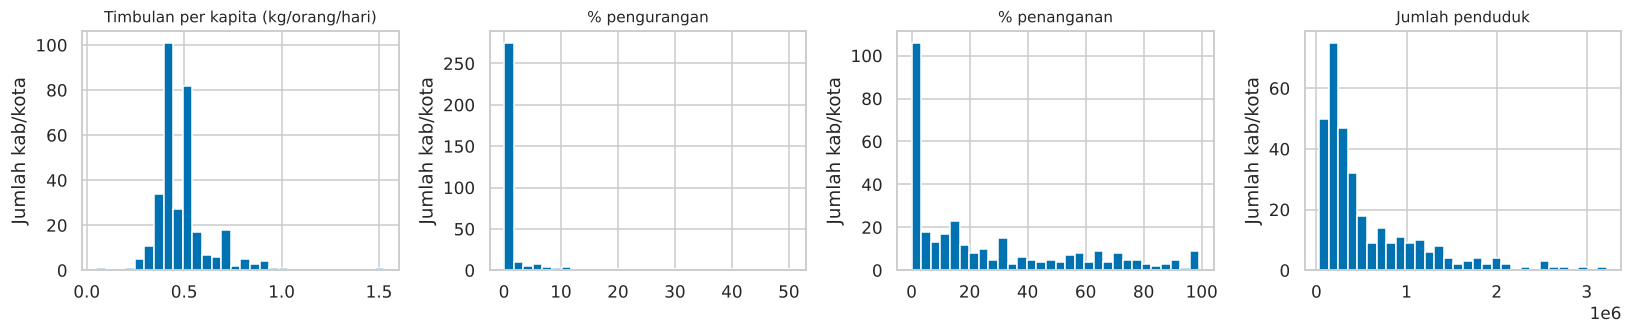

In [2]:
kandidat = ["timbulan_per_kapita", "pct_pengurangan", "pct_penanganan", "pct_tidak_terkelola", "jumlah_penduduk"]
print(df[kandidat].describe().round(2).T)

# Cek angka "bulat": nilai per kapita tepat 0,40 atau 0,50 kemungkinan angka asumsi, bukan hasil pengukuran
n_bulat = int(df["timbulan_per_kapita"].round(4).isin([0.4, 0.5]).sum())
print(f"\nWilayah dengan timbulan per kapita tepat 0,40 atau 0,50: {n_bulat} ({n_bulat / len(df) * 100:.1f}%)")
print(f"Wilayah dengan pct_pengurangan = 0: {int((df['pct_pengurangan'] == 0).sum())}")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, col, ttl in zip(axes,
        ["timbulan_per_kapita", "pct_pengurangan", "pct_penanganan", "jumlah_penduduk"],
        ["Timbulan per kapita (kg/orang/hari)", "% pengurangan", "% penanganan", "Jumlah penduduk"]):
    ax.hist(df[col], bins=30, color=PALET[0], edgecolor="white")
    ax.set_title(ttl, fontsize=10)
    ax.set_ylabel("Jumlah kab/kota")
plt.tight_layout()
plt.show()

**Analisis:** (1) Timbulan per kapita sangat terpusat di sekitar 0,40-0,51 kg/orang/hari (median 0,48), tetapi ada ekstrem: minimum 0,05 dan maksimum 1,53. (2) `pct_pengurangan` sangat miring: median hanya 0,04%, sebagian besar wilayah di sekitar nol, dan hanya segelintir yang mencapai 30-50%. (3) `pct_penanganan` menyebar lebar dari 0 sampai sekitar 99%, ini variabel yang paling membedakan antar wilayah. (4) Penduduk miring ke kanan (median sekitar 331 ribu, maksimum 3,2 juta). **Catatan kualitas:** sekitar 9,5% wilayah punya per kapita tepat 0,40 atau 0,50, yang kemungkinan angka asumsi dan bukan hasil pengukuran. Ini perlu disebut sebagai keterbatasan.

## 3. Pemilihan fitur

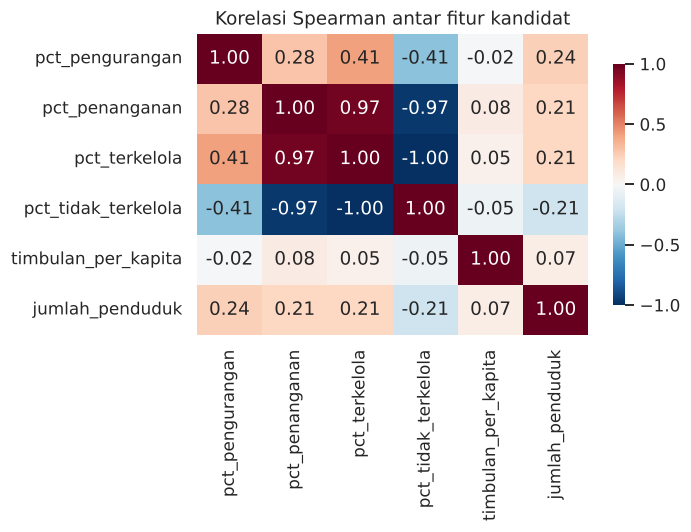

Fitur clustering: ['log_pengurangan', 'pct_penanganan', 'timbulan_per_kapita']
Bentuk matriks: (327, 3)


In [3]:
# pct_terkelola = pct_pengurangan + pct_penanganan, dan pct_tidak_terkelola = 100 - pct_terkelola.
# Ketiganya saling bergantung, jadi cukup pakai pct_pengurangan dan pct_penanganan.
corr = df[["pct_pengurangan", "pct_penanganan", "pct_terkelola", "pct_tidak_terkelola",
           "timbulan_per_kapita", "jumlah_penduduk"]].corr(method="spearman")
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar_kws={"shrink": .8})
plt.title("Korelasi Spearman antar fitur kandidat")
plt.tight_layout()
plt.show()

# pct_pengurangan sangat miring (banyak 0, beberapa sampai 50%), jadi pakai log1p agar tidak didominasi outlier
df["log_pengurangan"] = np.log1p(df["pct_pengurangan"])

FITUR = ["log_pengurangan", "pct_penanganan", "timbulan_per_kapita"]
scaler = StandardScaler()
X = scaler.fit_transform(df[FITUR])
print("Fitur clustering:", FITUR)
print("Bentuk matriks:", X.shape)

**Analisis:** `pct_terkelola` hampir identik dengan `pct_penanganan` (korelasi sekitar 0,97) dan `pct_tidak_terkelola` adalah kebalikan persisnya. Kalau semuanya dimasukkan, aspek pengelolaan akan terhitung dua sampai tiga kali dan mendominasi jarak antar titik. Karena itu hanya `pct_pengurangan` dan `pct_penanganan` yang dipakai. Timbulan per kapita nyaris tidak berkorelasi dengan keduanya (di bawah 0,1), artinya ia membawa informasi yang berbeda dan layak masuk. `pct_pengurangan` ditransformasi log1p karena sangat miring, lalu semua fitur distandarisasi karena skalanya berbeda jauh (persen vs kg).

## 4. Membandingkan set fitur

In [4]:
set_fitur = {
    "A: pengurangan + penanganan":                    ["log_pengurangan", "pct_penanganan"],
    "B: A + timbulan per kapita (dipilih)":           ["log_pengurangan", "pct_penanganan", "timbulan_per_kapita"],
    "C: B + log penduduk":                            ["log_pengurangan", "pct_penanganan", "timbulan_per_kapita", "log_penduduk"],
}
df["log_penduduk"] = np.log(df["jumlah_penduduk"])

baris = []
for nama, cols in set_fitur.items():
    Z = StandardScaler().fit_transform(df[cols])
    for k in (3, 4):
        lab = KMeans(k, n_init=30, random_state=42).fit_predict(Z)
        baris.append({"Set fitur": nama, "k": k,
                      "Silhouette": round(silhouette_score(Z, lab), 3),
                      "Davies-Bouldin": round(davies_bouldin_score(Z, lab), 3)})
pd.DataFrame(baris)

,Set fitur,k,Silhouette,Davies-Bouldin
0,A: pengurangan + penanganan,3,0.650,0.547
1,A: pengurangan + penanganan,4,0.630,0.802
2,B: A + timbulan per kapita (dipilih),3,0.461,0.898
3,B: A + timbulan per kapita (dipilih),4,0.488,0.808
4,C: B + log penduduk,3,0.330,1.230
5,C: B + log penduduk,4,0.350,1.077


**Analisis:** Set A (hanya pengurangan + penanganan) memang punya silhouette paling tinggi (0,63-0,65), tetapi ruangnya hanya 2 dimensi dan tidak memuat informasi timbulan sama sekali. Set B menambah timbulan per kapita dan silhouette turun ke 0,49, namun menghasilkan segmen yang bermakna (kota besar dengan sampah per orang tinggi). Set C menambah penduduk dan justru menurunkan kualitas (0,35) karena penduduk ikut mendominasi jarak tanpa menambah pola yang jelas. **Ini keputusan yang disengaja:** kami memilih B dengan sadar mengorbankan sebagian skor silhouette demi segmen yang lebih informatif. Kalau dosen lebih menekankan skor, Set A adalah alternatif yang sah.

## 5. Menentukan jumlah cluster (k)

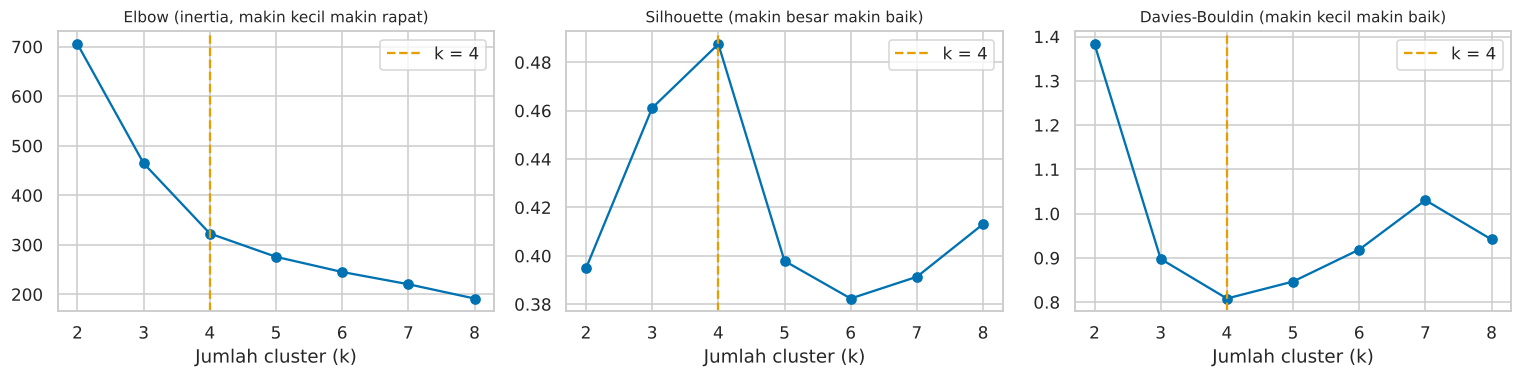

,k,inertia,silhouette,davies_bouldin
0,2,705.279,0.395,1.383
1,3,464.526,0.461,0.898
2,4,322.844,0.488,0.808
3,5,275.823,0.398,0.847
4,6,245.176,0.382,0.919
5,7,220.474,0.391,1.031
6,8,191.618,0.413,0.942


In [5]:
hasil_k = []
for k in range(2, 9):
    km = KMeans(k, n_init=30, random_state=42).fit(X)
    hasil_k.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(X, km.labels_),
                    "davies_bouldin": davies_bouldin_score(X, km.labels_)})
hasil_k = pd.DataFrame(hasil_k)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, ttl in zip(axes, ["inertia", "silhouette", "davies_bouldin"],
                        ["Elbow (inertia, makin kecil makin rapat)",
                         "Silhouette (makin besar makin baik)",
                         "Davies-Bouldin (makin kecil makin baik)"]):
    ax.plot(hasil_k["k"], hasil_k[col], marker="o", color=PALET[0])
    ax.axvline(4, color=PALET[1], linestyle="--", label="k = 4")
    ax.set_title(ttl, fontsize=10); ax.set_xlabel("Jumlah cluster (k)")
    ax.legend()
plt.tight_layout()
plt.show()
hasil_k.round(3)

**Analisis:** k = 4 memberi silhouette tertinggi (0,488) dan Davies-Bouldin terendah (0,808) sekaligus. Kurva elbow tidak patah tajam, tetapi penurunan inertia melambat setelah k = 4 (705 → 465 → 323 → 276), jadi tiga metrik sepakat pada k = 4. Silhouette sekitar 0,49 tergolong sedang: struktur kelompoknya ada, tetapi tidak terpisah tegas.

## 6. Model final: K-Means dengan k = 4

In [6]:
K = 4
km = KMeans(K, n_init=50, random_state=42).fit(X)

# Urutkan nomor cluster berdasarkan median % penanganan (0 = terendah) agar nomor stabil dan mudah dibaca
df["cluster_raw"] = km.labels_
urut = df.groupby("cluster_raw")["pct_penanganan"].median().sort_values().index
peta_nomor = {lama: baru for baru, lama in enumerate(urut)}
df["cluster"] = df["cluster_raw"].map(peta_nomor)

profil = df.groupby("cluster").agg(
    jumlah_wilayah=("cluster", "size"),
    median_penduduk=("jumlah_penduduk", "median"),
    median_per_kapita=("timbulan_per_kapita", "median"),
    median_pengurangan=("pct_pengurangan", "median"),
    median_penanganan=("pct_penanganan", "median"),
    median_tidak_terkelola=("pct_tidak_terkelola", "median"),
).round(2)

# Beri nama cluster berdasarkan ciri paling menonjol (aturan dibuat di kode supaya bisa direproduksi)
sisa = set(profil.index)
nama = {}
c = profil.loc[list(sisa), "median_penanganan"].idxmax();      nama[c] = "Penanganan tinggi";               sisa.discard(c)
c = profil.loc[list(sisa), "median_pengurangan"].idxmax();     nama[c] = "Pengurangan menonjol";            sisa.discard(c)
c = profil.loc[list(sisa), "median_per_kapita"].idxmax();      nama[c] = "Timbulan per kapita tinggi";       sisa.discard(c)
c = sisa.pop();                                                nama[c] = "Belum terkelola"
df["label_cluster"] = df["cluster"].map(nama)
profil.insert(0, "label", profil.index.map(nama))
profil

,label,jumlah_wilayah,median_penduduk,median_per_kapita,median_pengurangan,median_penanganan,median_tidak_terkelola
cluster,,,,,,,
0,Belum terkelola,176,287989.0,0.45,0.01,2.87,96.72
1,Timbulan per kapita tinggi,36,679371.5,0.73,0.04,17.89,80.11
2,Pengurangan menonjol,38,491090.5,0.42,12.02,22.80,63.71
3,Penanganan tinggi,77,334578.0,0.41,0.05,64.90,33.57


**Analisis:** Empat segmen terbentuk: (1) **Belum terkelola** (176 wilayah, 54%): penanganan median hanya 2,9% dan pengurangan nyaris nol. Ini segmen dominan. (2) **Timbulan per kapita tinggi** (36 wilayah): timbulan sekitar 0,73 kg/orang/hari dan penduduk median 679 ribu, yaitu kota-kota besar. Cluster ini dibentuk terutama oleh timbulan per kapita, sedangkan kinerja pengelolaannya campuran (lihat boxplot). (3) **Pengurangan menonjol** (38 wilayah): satu-satunya kelompok dengan pengurangan berarti (median 12%). (4) **Penanganan tinggi** (77 wilayah): penanganan median 65%, tidak terkelola hanya sekitar 34%. Nama cluster dibuat otomatis dari ciri paling menonjol, jadi bisa direproduksi.

## 7. Uji stabilitas cluster

In [7]:
# (a) Bootstrap: latih ulang pada sampel acak, lalu cek seberapa mirip hasilnya dengan model final (ARI = 1 berarti identik)
rng = np.random.default_rng(42)
ari_boot = []
for i in range(100):
    idx = rng.choice(len(X), len(X), replace=True)
    km_b = KMeans(K, n_init=10, random_state=i).fit(X[idx])
    ari_boot.append(adjusted_rand_score(df["cluster_raw"], km_b.predict(X)))

# (b) Algoritma lain: Ward hierarchical, apakah hasilnya mirip K-Means?
ward = AgglomerativeClustering(K, linkage="ward").fit_predict(X)
ari_ward = adjusted_rand_score(df["cluster_raw"], ward)

print(f"Silhouette model final  : {silhouette_score(X, km.labels_):.3f}")
print(f"Bootstrap ARI (100x)    : rata-rata {np.mean(ari_boot):.2f} | minimum {np.min(ari_boot):.2f}")
print(f"ARI K-Means vs Ward     : {ari_ward:.2f}")

Silhouette model final  : 0.488
Bootstrap ARI (100x)    : rata-rata 0.93 | minimum 0.79
ARI K-Means vs Ward     : 0.89


**Analisis:** Cluster ini stabil. Pada 100 kali bootstrap, kemiripan dengan model final (ARI) rata-rata 0,93 dengan minimum 0,79, dan algoritma Ward menghasilkan pengelompokan yang mirip (ARI 0,89). Artinya segmen bukan kebetulan dari inisialisasi acak atau pilihan algoritma. Perlu diingat stabil tidak sama dengan terpisah tegas: silhouette 0,49 tetap tergolong sedang.

In [ ]:
# Silhouette per cluster: cluster mana yang rapi dan mana yang lemah?
from sklearn.metrics import silhouette_samples

df["sil"] = silhouette_samples(X, df["cluster_raw"])
sil_cluster = df.groupby("label_cluster").agg(
    n_wilayah=("sil", "size"),
    silhouette_rata2=("sil", "mean"),
    n_negatif=("sil", lambda s: int((s < 0).sum())),
).round(3).sort_values("silhouette_rata2", ascending=False)
print("Silhouette keseluruhan:", round(df["sil"].mean(), 3))
print(f"Wilayah dengan silhouette negatif: {int((df['sil'] < 0).sum())} dari {len(df)}")
sil_cluster

**Analisis:** Silhouette keseluruhan 0,49 ternyata menyembunyikan perbedaan antar cluster. "Belum terkelola" paling rapi (sekitar 0,61, tidak ada anggota bersilhouette negatif), "Penanganan tinggi" (sekitar 0,40) dan "Pengurangan menonjol" (sekitar 0,37) cukup baik, sedangkan **"Timbulan per kapita tinggi" paling lemah (sekitar 0,19)** dan memuat 5 dari 9 wilayah bersilhouette negatif. Penyebabnya: cluster ini dibentuk oleh satu fitur (timbulan per kapita) yang sebagian nilainya membulat 0,40/0,50 (kemungkinan angka asumsi), sementara penanganannya menyebar 0 sampai 99% sehingga anggotanya bertumpang tindih dengan cluster lain. Jadi skor sedang bukan berarti seluruh segmen buruk: tiga segmen sehat, satu segmen bergantung pada kualitas data per kapita. Percobaan lain (winsorize atau log per kapita, RobustScaler, bobot fitur) tidak menaikkan skor secara berarti tanpa mengubah makna segmen, jadi set fitur B dipertahankan.

## 8. Visualisasi cluster

Varians dijelaskan PCA: [37.2 33.1] % | total 70.3 %


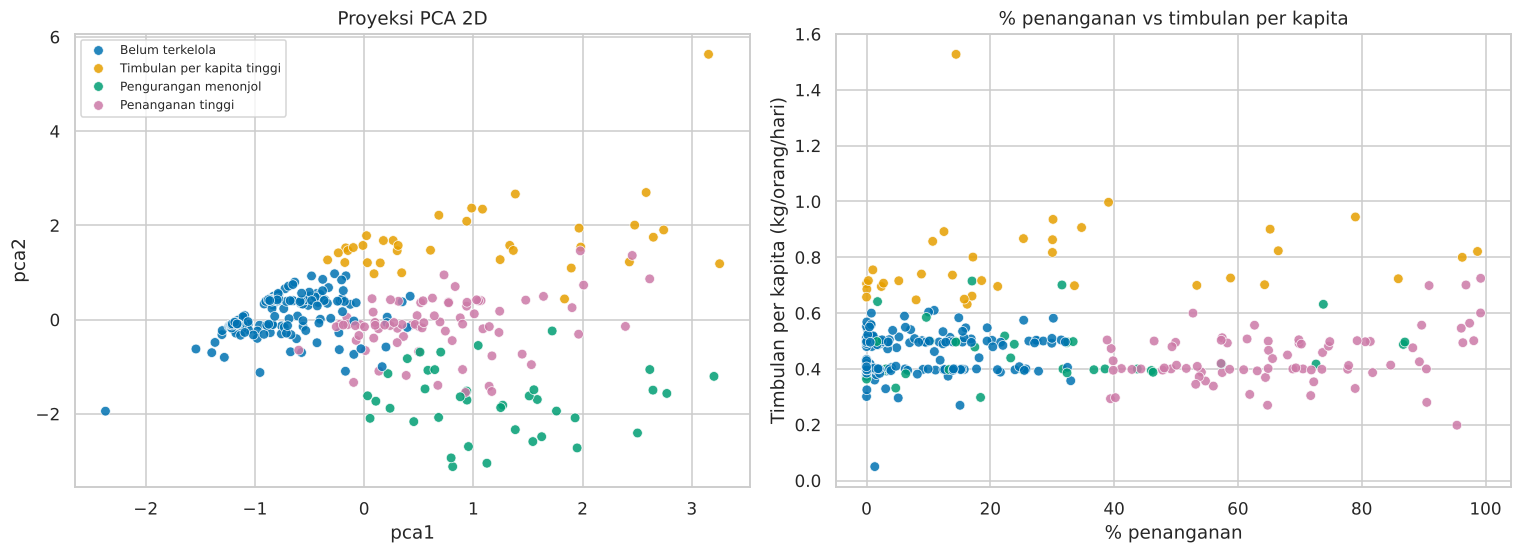

In [8]:
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
df["pca1"], df["pca2"] = P[:, 0], P[:, 1]
print("Varians dijelaskan PCA:", (pca.explained_variance_ratio_ * 100).round(1), "% | total",
      round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

urutan_label = [nama[i] for i in sorted(nama)]
warna = dict(zip(urutan_label, PALET))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.scatterplot(data=df, x="pca1", y="pca2", hue="label_cluster", hue_order=urutan_label,
                palette=warna, s=40, alpha=.85, ax=axes[0])
axes[0].set_title("Proyeksi PCA 2D"); axes[0].legend(title="", fontsize=8)

sns.scatterplot(data=df, x="pct_penanganan", y="timbulan_per_kapita", hue="label_cluster",
                hue_order=urutan_label, palette=warna, s=40, alpha=.85, ax=axes[1], legend=False)
axes[1].set_title("% penanganan vs timbulan per kapita")
axes[1].set_xlabel("% penanganan"); axes[1].set_ylabel("Timbulan per kapita (kg/orang/hari)")
plt.tight_layout()
plt.show()

**Analisis:** Dua komponen PCA menangkap 70,3% variasi, cukup representatif untuk visualisasi. "Belum terkelola" membentuk gumpalan padat di sisi kiri, "Penanganan tinggi" dan "Pengurangan menonjol" menyebar ke kanan, dan "Timbulan per kapita tinggi" terpisah di bagian atas. Ada tumpang tindih di bagian tengah, wajar karena silhouette hanya sedang. Pada grafik kanan terlihat jelas bahwa kelompok kuning dipisahkan oleh timbulan per kapita (di atas sekitar 0,63), bukan oleh persen penanganan.

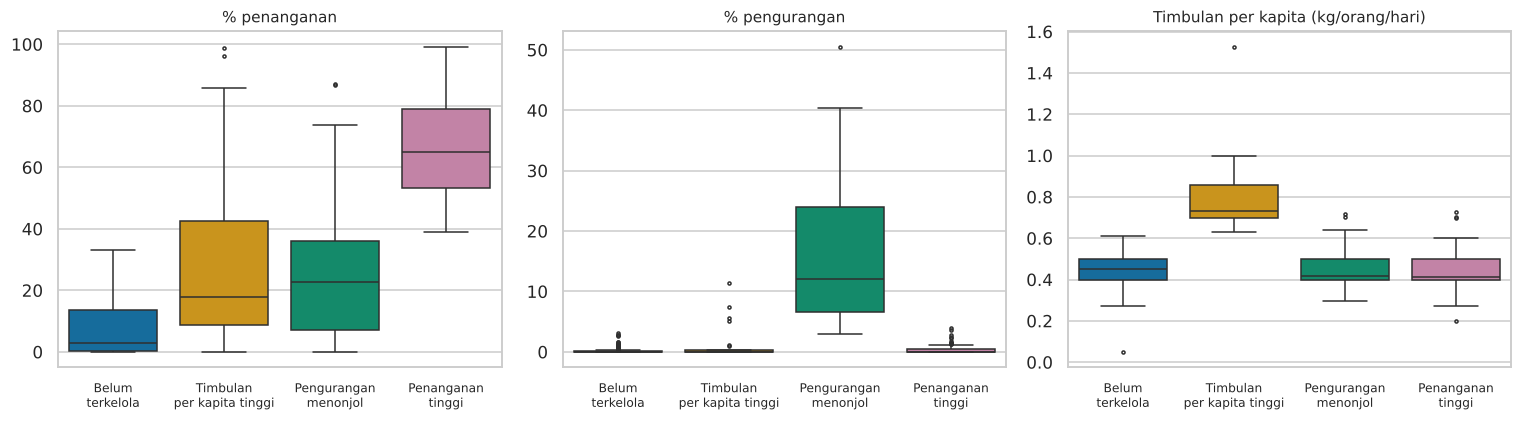

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, ttl in zip(axes, ["pct_penanganan", "pct_pengurangan", "timbulan_per_kapita"],
                        ["% penanganan", "% pengurangan", "Timbulan per kapita (kg/orang/hari)"]):
    sns.boxplot(data=df, x="label_cluster", y=col, order=urutan_label, palette=warna, ax=ax, fliersize=2)
    ax.set_title(ttl, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticklabels([t.get_text().replace(", ", ",\n").replace(" ", "\n", 1) for t in ax.get_xticklabels()], fontsize=8)
plt.tight_layout()
plt.show()

**Analisis:** Boxplot memperjelas karakter tiap cluster. Penanganan tinggi memang tinggi (median sekitar 65%), pengurangan hanya benar-benar tinggi di cluster "Pengurangan menonjol" (median 12%, hingga 40-50%), dan timbulan per kapita hanya menonjol di cluster "Timbulan per kapita tinggi". Perhatikan bahwa cluster "Timbulan per kapita tinggi" punya penanganan yang menyebar lebar (0 sampai sekitar 99%). Karena itu cluster ini sengaja diberi nama berdasarkan timbulannya, bukan berdasarkan kinerja pengelolaan.

## 9. Sebaran cluster per provinsi

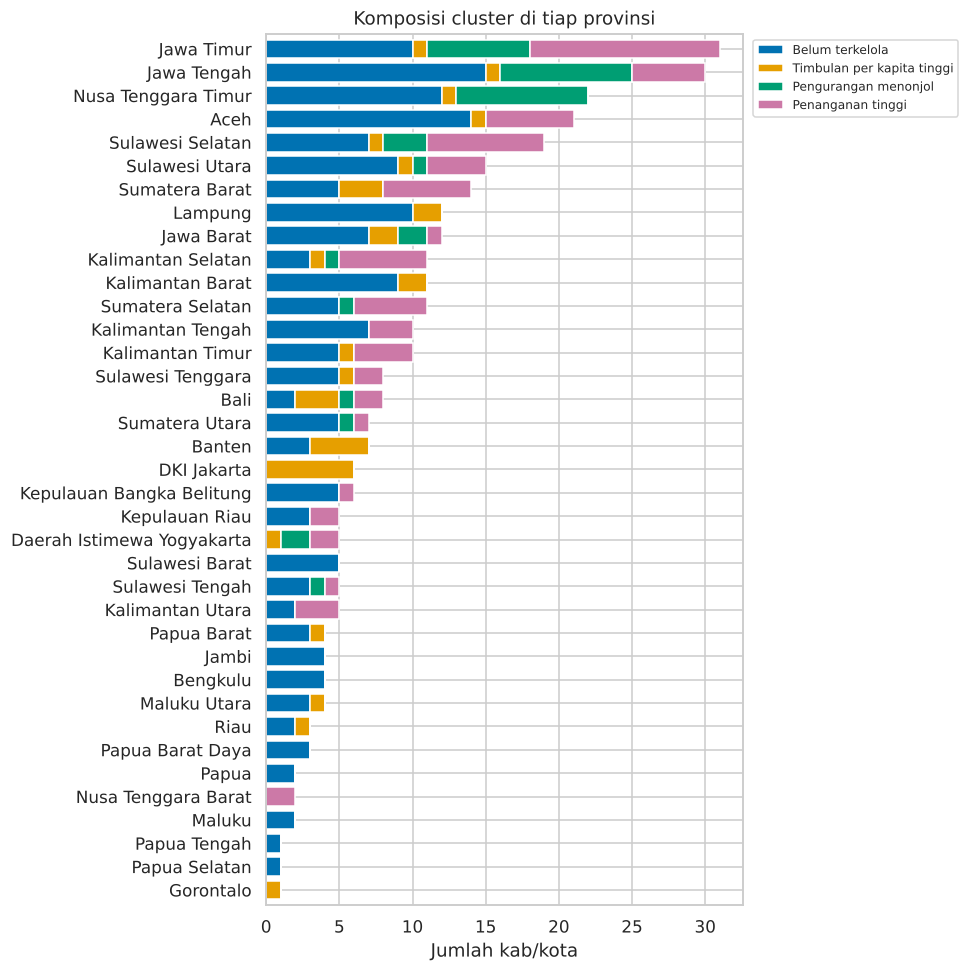

,n_wilayah,pct_belum_terkelola
provinsi,,
Sulawesi Barat,5,100.0
Lampung,12,83.0
Kepulauan Bangka Belitung,6,83.0
Kalimantan Barat,11,82.0
Sumatera Utara,7,71.0
Kalimantan Tengah,10,70.0
Aceh,21,67.0
Sulawesi Tenggara,8,62.0


In [10]:
tab = pd.crosstab(df["provinsi"], df["label_cluster"])[urutan_label]
tab = tab.loc[tab.sum(axis=1).sort_values().index]
ax = tab.plot(kind="barh", stacked=True, figsize=(9, 9), color=[warna[l] for l in urutan_label], width=.8)
ax.set_xlabel("Jumlah kab/kota"); ax.set_ylabel("")
ax.set_title("Komposisi cluster di tiap provinsi")
ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

# Provinsi dengan kab/kota paling banyak di cluster "Belum terkelola" (minimal 5 wilayah supaya persentase bermakna)
n_prov = df.groupby("provinsi").size()
pct_belum = (df["label_cluster"].eq("Belum terkelola").groupby(df["provinsi"]).mean() * 100).round(0)
pd.DataFrame({"n_wilayah": n_prov, "pct_belum_terkelola": pct_belum}).query("n_wilayah >= 5") \
  .sort_values("pct_belum_terkelola", ascending=False).head(8)

**Analisis:** Jawa Timur dan Jawa Tengah punya keempat segmen sekaligus, artinya kondisi antar kab/kota di dalam satu provinsi sangat beragam, jadi ranking per provinsi saja bisa menyesatkan. DKI Jakarta seluruhnya (6 wilayah) masuk "Timbulan per kapita tinggi". Provinsi dengan proporsi "Belum terkelola" tertinggi (minimal 5 wilayah): Sulawesi Barat (100%), Lampung dan Kepulauan Bangka Belitung (83%), Kalimantan Barat (82%). **Hati-hati:** beberapa provinsi hanya punya 1-3 wilayah dalam data (mis. Papua Tengah, Papua Selatan, Gorontalo), dan data mencakup 327 wilayah dari sekitar 514 kab/kota di Indonesia. Jangan menyimpulkan kondisi provinsi dari sampel sekecil itu.

## 10. Contoh anggota tiap cluster

In [11]:
for lbl in urutan_label:
    sub = df[df["label_cluster"] == lbl].nlargest(5, "jumlah_penduduk")
    print(f"\n{lbl} ({(df['label_cluster'] == lbl).sum()} wilayah) - 5 penduduk terbanyak")
    print(sub[["kab_kota", "provinsi", "pct_pengurangan", "pct_penanganan", "timbulan_per_kapita"]]
          .round(2).to_string(index=False))


Belum terkelola (176 wilayah) - 5 penduduk terbanyak
          kab_kota    provinsi  pct_pengurangan  pct_penanganan  timbulan_per_kapita
       Kab. Jember  Jawa Timur             0.02            0.18                 0.40
      Kab. Cirebon  Jawa Barat             0.00            2.23                 0.50
       Kab. Brebes Jawa Tengah             0.02            3.39                 0.50
    Kab. Indramayu  Jawa Barat             0.82           25.39                 0.57
Kab. Bandung Barat  Jawa Barat             0.25           32.99                 0.36

Timbulan per kapita tinggi (36 wilayah) - 5 penduduk terbanyak
                 kab_kota    provinsi  pct_pengurangan  pct_penanganan  timbulan_per_kapita
  Kota Adm. Jakarta Timur DKI Jakarta             0.00           13.88                 0.74
              Kota Bekasi  Jawa Barat             0.00            5.21                 0.72
  Kota Adm. Jakarta Barat DKI Jakarta             0.00           25.35                 0.87
Kota

**Analisis:** Daftar ini memberi gambaran konkret segmen. "Timbulan per kapita tinggi" berisi kota besar (Jakarta Timur, Bekasi, Jakarta Barat, Jakarta Selatan, Depok). "Penanganan tinggi" dipimpin Kota Surabaya (99,2%), diikuti Kab. Malang, Sidoarjo, dan Banyuwangi, semuanya Jawa Timur. "Pengurangan menonjol" berisi Kab. Banyumas (31,7%), Kota Semarang (30,0%), dan Kab. Kediri (27,5%). Catatan: Kab. Cilacap (pengurangan 3,7%) berada di dekat batas antar cluster, dan kabupaten padat penduduk seperti Jember, Cirebon, dan Brebes ada di "Belum terkelola", cocok untuk disorot di dashboard sebagai wilayah prioritas.

## 11. Klasifikasi (bagian 1): decision tree untuk menjelaskan aturan cluster

Tujuannya **interpretasi, bukan prediksi**. Label cluster dibentuk dari fitur yang sama, jadi akurasi tinggi memang wajar dan tidak boleh diklaim sebagai kemampuan memprediksi. Yang dicari adalah aturan "jika-maka" yang mudah dijelaskan di presentasi.

Akurasi tree (menjelaskan cluster): 0.976

|--- pct_penanganan <= 38.70
|   |--- pct_pengurangan <= 2.94
|   |   |--- timbulan_per_kapita <= 0.62
|   |   |   |--- class: Belum terkelola
|   |   |--- timbulan_per_kapita >  0.62
|   |   |   |--- class: Timbulan per kapita tinggi
|   |--- pct_pengurangan >  2.94
|   |   |--- timbulan_per_kapita <= 0.50
|   |   |   |--- class: Pengurangan menonjol
|   |   |--- timbulan_per_kapita >  0.50
|   |   |   |--- class: Pengurangan menonjol
|--- pct_penanganan >  38.70
|   |--- timbulan_per_kapita <= 0.70
|   |   |--- pct_pengurangan <= 3.25
|   |   |   |--- class: Penanganan tinggi
|   |   |--- pct_pengurangan >  3.25
|   |   |   |--- class: Pengurangan menonjol
|   |--- timbulan_per_kapita >  0.70
|   |   |--- class: Timbulan per kapita tinggi



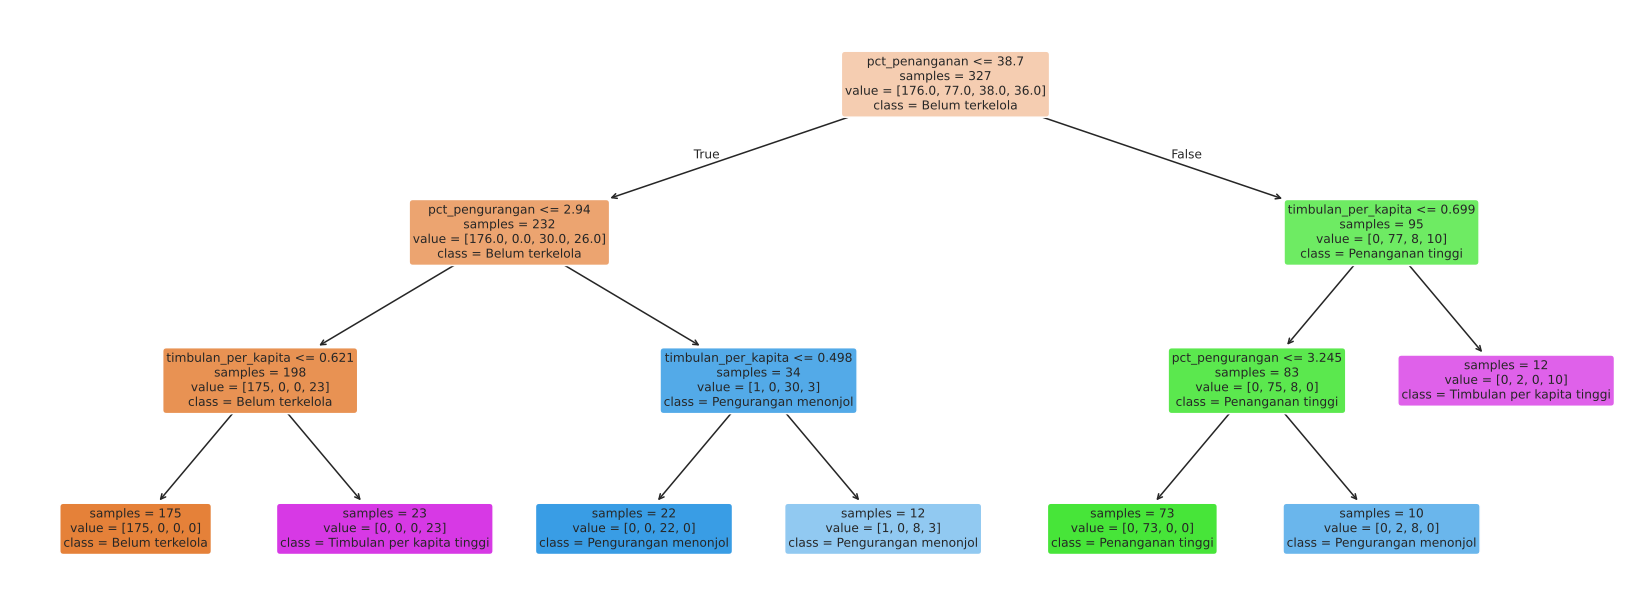

In [12]:
fitur_mentah = ["pct_pengurangan", "pct_penanganan", "timbulan_per_kapita"]
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=42)
tree.fit(df[fitur_mentah], df["label_cluster"])

print("Akurasi tree (menjelaskan cluster):", round(tree.score(df[fitur_mentah], df["label_cluster"]), 3))
print()
print(export_text(tree, feature_names=fitur_mentah))

plt.figure(figsize=(19, 7))
plot_tree(tree, feature_names=fitur_mentah, class_names=list(tree.classes_), filled=True,
          rounded=True, fontsize=8, impurity=False)
plt.show()

**Analisis:** Decision tree dengan kedalaman 3 menjelaskan cluster dengan akurasi 97,6%. Ingat, angka ini **bukan kemampuan prediksi**, hanya bukti bahwa aturan sederhana cukup menjelaskan cluster. Aturan utama: (1) penanganan di atas 38,7% dan pengurangan di bawah sekitar 3% berarti "Penanganan tinggi"; (2) penanganan di bawah 38,7% dan pengurangan di bawah sekitar 3% berarti "Belum terkelola"; (3) pengurangan di atas sekitar 3% berarti "Pengurangan menonjol"; (4) timbulan per kapita di atas sekitar 0,62-0,70 mengarah ke "Timbulan per kapita tinggi". Terlihat satu pemisahan yang redundan (kedua cabang menghasilkan "Pengurangan menonjol"), itu hal wajar pada tree kecil dan tidak mengubah kesimpulan.

## 12. Klasifikasi (bagian 2): bisakah cluster diprediksi dari karakteristik wilayah?

Pertanyaan yang lebih bermakna: kalau kita **hanya tahu jumlah penduduk dan jenis wilayah (kota/kabupaten)**, bisakah kita menebak cluster pengelolaannya? Validasi memakai **GroupKFold per provinsi** supaya wilayah satu provinsi tidak muncul di data latih dan uji sekaligus.

In [13]:
df["is_kota"] = df["kab_kota"].str.startswith("Kota").astype(int)
Xk = df[["log_penduduk", "is_kota"]]
y = df["label_cluster"]
gkf = GroupKFold(n_splits=5)

model = {
    "Tebak kelas mayoritas (baseline)": DummyClassifier(strategy="most_frequent"),
    "Random Forest":                    RandomForestClassifier(300, min_samples_leaf=5, random_state=42),
    "Random Forest (class_weight)":     RandomForestClassifier(300, min_samples_leaf=5, class_weight="balanced", random_state=42),
}
hasil = []
for n, m in model.items():
    pred = cross_val_predict(m, Xk, y, cv=gkf, groups=df["provinsi"])
    hasil.append({"Model": n, "Akurasi": round(accuracy_score(y, pred), 3),
                  "F1 macro": round(f1_score(y, pred, average="macro"), 3)})
print(pd.DataFrame(hasil).to_string(index=False))

# Rincian per cluster: seberapa sering cluster ini berhasil ditebak benar (recall) oleh Random Forest
pred_rf = cross_val_predict(model["Random Forest"], Xk, y, cv=gkf, groups=df["provinsi"])
rincian = pd.DataFrame({
    "n_wilayah": y.value_counts(),
    "recall_RF": pd.Series({l: (pred_rf[y == l] == l).mean() for l in y.unique()}).round(2),
    "pct_wilayah_kota": df.groupby("label_cluster")["is_kota"].mean().mul(100).round(0),
}).loc[urutan_label]
rincian

                           Model  Akurasi  F1 macro
Tebak kelas mayoritas (baseline)    0.538     0.175
                   Random Forest    0.557     0.349
    Random Forest (class_weight)    0.352     0.289


,n_wilayah,recall_RF,pct_wilayah_kota
Belum terkelola,176,0.90,11.0
Timbulan per kapita tinggi,36,0.53,78.0
Pengurangan menonjol,38,0.00,24.0
Penanganan tinggi,77,0.06,18.0


**Analisis:** Hasilnya jujur dan negatif. Tebakan kelas mayoritas sudah mencapai akurasi 53,8%, sedangkan Random Forest hanya 55,7% (selisih sekitar 2 poin, tidak bermakna), dan versi class_weight malah turun ke 35,2%. Rincian recall menjelaskan alasannya: model hanya cukup bisa mengenali "Timbulan per kapita tinggi" (recall 0,53, karena 78% anggotanya adalah kota) dan "Belum terkelola" (kelas terbesar, recall 0,90). Cluster "Pengurangan menonjol" dan "Penanganan tinggi" hampir tidak bisa ditebak (recall 0,00 dan 0,06). **Kesimpulan:** jumlah penduduk dan jenis wilayah tidak menjelaskan kualitas pengelolaan sampah. Faktor penentunya kemungkinan kebijakan, anggaran, dan fasilitas daerah (TPA, TPS3R, bank sampah) yang tidak ada di dataset ini.

## 13. Ekspor hasil untuk dashboard

In [14]:
kolom_out = ["provinsi", "kab_kota", "cluster", "label_cluster", "jumlah_penduduk", "timbulan_harian",
             "timbulan_per_kapita", "pct_pengurangan", "pct_penanganan", "pct_terkelola",
             "pct_tidak_terkelola", "pca1", "pca2"]
hasil_df = df[kolom_out].sort_values(["cluster", "provinsi", "kab_kota"])
hasil_df.to_csv("hasil_clustering_sampah_2025.csv", index=False)
profil.to_csv("profil_cluster_sampah_2025.csv")

print("Tersimpan: hasil_clustering_sampah_2025.csv ->", hasil_df.shape)
print("Tersimpan: profil_cluster_sampah_2025.csv  ->", profil.shape)
hasil_df.head()

Tersimpan: hasil_clustering_sampah_2025.csv -> (327, 13)
Tersimpan: profil_cluster_sampah_2025.csv  -> (4, 7)


,provinsi,kab_kota,cluster,label_cluster,jumlah_penduduk,timbulan_harian,timbulan_per_kapita,pct_pengurangan,pct_penanganan,pct_terkelola,pct_tidak_terkelola,pca1,pca2
1,Aceh,Kab. Aceh Barat Daya,0,Belum terkelola,156737.0,80.6700,0.514684,0.92,5.24,6.17,93.832899,-0.305650,0.028257
3,Aceh,Kab. Aceh Jaya,0,Belum terkelola,101815.0,50.9075,0.500000,0.00,1.51,1.51,98.488788,-0.833559,0.435263
4,Aceh,Kab. Aceh Selatan,0,Belum terkelola,240613.0,96.7976,0.402296,0.00,0.05,0.05,99.947313,-1.200733,-0.080353
5,Aceh,Kab. Aceh Singkil,0,Belum terkelola,141435.0,56.0000,0.395942,0.00,11.14,11.14,88.857632,-0.957208,-0.116968
6,Aceh,Kab. Aceh Tengah,0,Belum terkelola,234710.0,115.0079,0.490000,0.00,2.68,2.68,97.321054,-0.839595,0.382126


**Analisis:** Dua file hasil siap diserahkan ke anggota yang membuat dashboard: `hasil_clustering_sampah_2025.csv` (327 baris, berisi label cluster, metrik utama, dan koordinat PCA) dan `profil_cluster_sampah_2025.csv` (ringkasan 4 cluster). Kolom `label_cluster` bisa langsung dipakai sebagai warna atau filter.

## 14. Kesimpulan dan keterbatasan

**Kesimpulan**
1. Kab/kota bisa dikelompokkan menjadi **4 segmen** dengan K-Means (k = 4, silhouette 0,49, stabil: ARI bootstrap rata-rata 0,93): *Belum terkelola* (176), *Penanganan tinggi* (77), *Pengurangan menonjol* (38), dan *Timbulan per kapita tinggi* (36).
2. Lebih dari separuh wilayah (54%) berada di segmen "Belum terkelola" dengan penanganan median hanya 2,9%.
3. Decision tree menunjukkan segmen bisa dijelaskan dengan aturan sederhana (ambang penanganan sekitar 38,7%, pengurangan sekitar 3%, timbulan per kapita sekitar 0,62-0,70).
4. Segmen **tidak bisa diprediksi** dari jumlah penduduk dan jenis wilayah (akurasi 55,7% vs baseline 53,8%). Hanya kota besar dengan timbulan tinggi yang agak bisa dikenali.

**Keterbatasan (wajib disebut saat presentasi)**
- Data hanya 1 tahun (2025), jadi tidak ada analisis tren atau peramalan, dan cluster adalah potret sesaat.
- Cakupan 327 wilayah dari sekitar 514 kab/kota; beberapa provinsi hanya punya 1-3 wilayah sehingga perbandingan antar provinsi tidak seimbang.
- Sekitar 9,5% nilai timbulan per kapita tepat 0,40 atau 0,50 (kemungkinan angka asumsi), dan ada nilai ekstrem (Denpasar 1,53 dan Padang Pariaman 0,05 kg/orang/hari). Cluster "Timbulan per kapita tinggi" sebagian bergantung pada kualitas angka ini.
- Silhouette 0,49 berarti cluster cukup stabil tetapi tidak terpisah tegas, terutama di bagian tengah ruang PCA. Rinciannya: tiga cluster sehat (0,37-0,61), sedangkan "Timbulan per kapita tinggi" lemah (sekitar 0,19) karena bergantung pada angka per kapita yang sebagian membulat.
- Clustering bersifat **deskriptif**: ia mengelompokkan wilayah yang mirip, bukan menjelaskan penyebab. Tabel komposisi dan sumber sampah tidak dipakai karena banyak yang kosong dan ada anomali satuan.